<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Power Query & Data Wrangling Assignment<br></h3></center>

# Introduction
This Jupyter notebook is part of your learning experience in modern data wrangling, cleaning pipelines, and Power Query ETL (Extract, Transform, Load) methodologies. In this assignment, you will resolve common real-world data quality anomalies (leading/trailing whitespace, error values, missing categories), execute table appends and relational merges, extract text components, and engineer payroll compensation metrics.

### Key Objectives:
1. **Data Quality Diagnostic Audit**: Systematically identify dirty data patterns, including whitespace noise, `#ERROR` values, and unassigned categorical fields.
2. **Text Cleaning & Normalization**: Apply text trimming (`Text.Trim` / `.str.strip()`) and handle error records via conditional imputation.
3. **Feature Extraction**: Parse delimited email strings into distinct operational identifiers (`EmpID` username and `EmpDomain` corporate host).
4. **Appending Queries (Union Transformation)**: Append incoming employee batches (`MoreEmployees`) into a unified 110-person workforce cohort.
5. **Relational Merging (Join Transformation)**: Perform left relational joins against organizational lookup tables (`DepartmentData`) to assign department heads and branch locations.
6. **Payroll Engineering**: Formulate calculated columns for bonus compensation, total annual liability, and operational tenure.
7. **Exploratory Visual Analytics**: Synthesize workforce metrics into an executive analytics dashboard.

---
## Task 1 - Environment Setup & Raw Data Ingestion

Load core data science packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and ingest the uncleaned employee dataset (`PowerQuery_Employee_RawData.csv`).

In [1]:
# Import analytical packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')

# Set aesthetic styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load the raw dataset
df_raw = pd.read_csv('PowerQuery_Employee_RawData.csv')
print(f"Raw Dataset Shape: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns")
print("\nFirst 6 records of uncleaned raw data:")
display(df_raw.head(6))


Raw Dataset Shape: 100 rows × 7 columns

First 6 records of uncleaned raw data:


,Full Name,Email,Department,Join Date,End Date,Salary,Bonus %
0,Employee 1,#ERROR,Sales,2022-10-10,2022-11-30,86422,0.06
1,Employee 2,emp2@company.com,Finance,2023-09-13,2023-10-25,45795,0.12
2,Employee 3,emp3@company.com,NaN,2022-08-11,2022-09-02,30860,0.13
3,Employee 4,emp4@company.com,IT,2022-06-11,2022-08-04,68158,0.10
4,Employee 5,emp5@company.com,HR,2023-05-31,2023-06-24,84343,0.22
5,Employee 6,emp6@company.com,NaN,2022-06-10,2022-08-05,74732,0.12


---
## Task 2 - Data Quality Diagnostic Audit

Prior to transformation, we audit the three major data hygiene defects present in the raw extraction:
1. **Whitespace Inconsistencies**: Leading/trailing padding in `Full Name` strings (e.g. `'  Employee 1  '`).
2. **Calculation / Scraping Errors**: `#ERROR` values in `Email` fields.
3. **Missing Categoricals**: Missing or null entries in `Department`.

In [2]:
# 1. Detect whitespace padding in Full Name
whitespace_mask = df_raw['Full Name'].str.startswith(' ') | df_raw['Full Name'].str.endswith(' ')
whitespace_count = whitespace_mask.sum()

# 2. Detect #ERROR or invalid emails
error_email_mask = (df_raw['Email'] == '#ERROR') | df_raw['Email'].isnull()
error_email_count = error_email_mask.sum()

# 3. Detect missing departments
missing_dept_mask = df_raw['Department'].isnull() | (df_raw['Department'] == '')
missing_dept_count = missing_dept_mask.sum()

print("=== Data Quality Audit Findings ===")
print(f"1. Full Name records requiring TRIM:       {whitespace_count} rows")
print(f"2. Email records with #ERROR or missing:    {error_email_count} rows")
print(f"3. Records with Missing/Unassigned Dept:   {missing_dept_count} rows")

# Display sample defective records
print("\nSample Defective Records in Raw Table:")
display(df_raw[whitespace_mask | error_email_mask | missing_dept_mask].head(6))


=== Data Quality Audit Findings ===
1. Full Name records requiring TRIM:       10 rows
2. Email records with #ERROR or missing:    7 rows
3. Records with Missing/Unassigned Dept:   19 rows

Sample Defective Records in Raw Table:


,Full Name,Email,Department,Join Date,End Date,Salary,Bonus %
0,Employee 1,#ERROR,Sales,2022-10-10,2022-11-30,86422,0.06
2,Employee 3,emp3@company.com,NaN,2022-08-11,2022-09-02,30860,0.13
5,Employee 6,emp6@company.com,NaN,2022-06-10,2022-08-05,74732,0.12
10,Employee 11,emp11@company.com,NaN,2022-12-23,2023-01-12,67194,0.06
15,Employee 16,#ERROR,HR,2023-07-31,2023-09-12,71090,0.21
16,Employee 17,emp17@company.com,NaN,2023-05-21,2023-06-19,31685,0.19


---
## Task 3 - Text Cleaning & Value Imputation

We apply the Power Query equivalent transformations:
- **`Text.Trim`**: Strip extraneous whitespace padding from employee names.
- **`Replace Errors`**: Impute valid standardized corporate emails (`emp{id}@company.com`) for damaged `#ERROR` records.
- **`Replace Values`**: Impute missing department values with `'NA'` (Unassigned).

In [3]:
# Create clean working copy
df_clean = df_raw.copy()

# 1. Apply TRIM to Full Name
df_clean['Full Name'] = df_clean['Full Name'].astype(str).str.strip()

# 2. Add sequential index (1 to 100)
df_clean['Sr.No'] = np.arange(1, len(df_clean) + 1)

# 3. Impute #ERROR emails
cleaned_emails = []
for idx, email in zip(df_clean['Sr.No'], df_clean['Email']):
    if str(email).strip() == '#ERROR' or pd.isna(email) or '@' not in str(email):
        cleaned_emails.append(f'emp{idx}@company.com')
    else:
        cleaned_emails.append(str(email).strip())

df_clean['Email'] = cleaned_emails

# 4. Impute missing Department
df_clean['Department'] = df_clean['Department'].fillna('NA').replace('', 'NA')

print("✅ Text Cleaning Completed!")
print(f"Remaining whitespace in Full Name: {(df_clean['Full Name'].str.startswith(' ') | df_clean['Full Name'].str.endswith(' ')).sum()}")
print(f"Remaining #ERROR in Email:        {(df_clean['Email'] == '#ERROR').sum()}")
print(f"Remaining null Departments:       {df_clean['Department'].isnull().sum()}")


✅ Text Cleaning Completed!
Remaining whitespace in Full Name: 0
Remaining #ERROR in Email:        0
Remaining null Departments:       0


---
## Task 4 - Feature Extraction: Username (`EmpID`) & Domain (`EmpDomain`)

Using string splitting (Power Query *Split Column by Delimiter `@`*), we decouple the email address into:
- **`EmpID`**: User handle before `@`
- **`EmpDomain`**: Corporate domain host after `@`

In [4]:
# Split Email by '@' delimiter
email_parts = df_clean['Email'].str.split('@', expand=True)
df_clean['EmpID'] = email_parts[0]
df_clean['EmpDomain'] = email_parts[1]

print("=== Sample Parsed Email Features ===")
display(df_clean[['Sr.No', 'Full Name', 'Email', 'EmpID', 'EmpDomain']].head(6))


=== Sample Parsed Email Features ===


,Sr.No,Full Name,Email,EmpID,EmpDomain
0,1,Employee 1,emp1@company.com,emp1,company.com
1,2,Employee 2,emp2@company.com,emp2,company.com
2,3,Employee 3,emp3@company.com,emp3,company.com
3,4,Employee 4,emp4@company.com,emp4,company.com
4,5,Employee 5,emp5@company.com,emp5,company.com
5,6,Employee 6,emp6@company.com,emp6,company.com


---
## Task 5 - Appending Queries: Integrating New Hire Cohort (`MoreEmployees`)

We ingest the incoming cohort of 10 new personnel (New Employee 101 to 110), clean their names and features, and append them via union (`pd.concat()`, equivalent to Power Query *Append Queries*).

In [5]:
# Define new employees dataset
more_employees_data = {
    'Full Name': ['New Employee 101', 'New Employee 102', 'New Employee 103', 'New Employee 104', 'New Employee 105',
                  'New Employee 106', 'New Employee 107', 'New Employee 108', 'New Employee 109', 'New Employee 110'],
    'Email': ['newemp101@company.com', 'newemp102@company.com', 'newemp103@company.com', 'newemp104@company.com', 'newemp105@company.com',
              'newemp106@company.com', 'newemp107@company.com', 'newemp108@company.com', 'newemp109@company.com', 'newemp110@company.com'],
    'Department': ['Marketing', 'Finance', 'Finance', 'Sales', 'Marketing', 'Sales', 'Finance', 'HR', 'HR', 'IT'],
    'Join Date': ['2024-02-07', '2024-06-10', '2024-01-08', '2024-01-12', '2024-04-02', '2024-04-28', '2024-06-02', '2024-01-08', '2024-04-08', '2024-03-08'],
    'End Date': ['2024-07-10', '2024-07-02', '2024-07-13', '2024-07-25', '2024-07-06', '2024-07-24', '2024-07-22', '2024-07-03', '2024-07-26', '2024-07-17'],
    'Salary': [44688, 57342, 69157, 34327, 72772, 72545, 32197, 55509, 66698, 47087],
    'Bonus %': [0.21, 0.08, 0.15, 0.19, 0.22, 0.12, 0.09, 0.19, 0.21, 0.12]
}
df_more = pd.DataFrame(more_employees_data)
df_more['Full Name'] = df_more['Full Name'].str.strip()
df_more['Sr.No'] = np.arange(101, 111)

# Extract EmpID and EmpDomain for new cohort
new_parts = df_more['Email'].str.split('@', expand=True)
df_more['EmpID'] = new_parts[0]
df_more['EmpDomain'] = new_parts[1]

# Append tables
df_appended = pd.concat([df_clean, df_more], ignore_index=True)
print(f"✅ Appended Total Workforce: {len(df_appended)} records (100 baseline + 10 incoming)")


✅ Appended Total Workforce: 110 records (100 baseline + 10 incoming)


---
## Task 6 - Relational Merging: Departmental Lookup Joins

We define the organizational reference lookup table (`DepartmentData`) and execute a left outer join on `Department` (Power Query *Merge Queries* / Excel `VLOOKUP`) to map **`Department Head`** and branch **`Location`**.

In [6]:
# Define Department hierarchy reference data
dept_reference = {
    'Department': ['HR', 'Sales', 'Marketing', 'IT', 'Finance'],
    'Department Head': ['Alice', 'Bob', 'Charlie', 'Diana', 'Ethan'],
    'Location': ['Mumbai', 'Delhi', 'Bangalore', 'Hyderabad', 'Pune']
}
df_dept = pd.DataFrame(dept_reference)

# Execute left join
df_master = df_appended.merge(df_dept, on='Department', how='left')

# Handle unassigned departments
df_master['Department Head'] = df_master['Department Head'].fillna('NA')
df_master['Location'] = df_master['Location'].fillna('NA')

print("=== Department Reference Table ===")
display(df_dept)

print("\nSample Merged Records with Department Head and Location:")
display(df_master[['Sr.No', 'Full Name', 'Department', 'Department Head', 'Location']].iloc[[0, 1, 2, 3, 4, 100, 109]])


=== Department Reference Table ===


,Department,Department Head,Location
0,HR,Alice,Mumbai
1,Sales,Bob,Delhi
2,Marketing,Charlie,Bangalore
3,IT,Diana,Hyderabad
4,Finance,Ethan,Pune



Sample Merged Records with Department Head and Location:


,Sr.No,Full Name,Department,Department Head,Location
0,1,Employee 1,Sales,Bob,Delhi
1,2,Employee 2,Finance,Ethan,Pune
2,3,Employee 3,NA,NA,NA
3,4,Employee 4,IT,Diana,Hyderabad
4,5,Employee 5,HR,Alice,Mumbai
100,101,New Employee 101,Marketing,Charlie,Bangalore
109,110,New Employee 110,IT,Diana,Hyderabad


---
## Task 7 - Calculated Columns & Payroll Engineering

We engineer the financial and temporal metrics:
1. **`Bonus Amount`**:
   $$\text{Bonus Amount} = \text{Salary} \times \text{Bonus \%}$$
2. **`Total Compensation`**:
   $$\text{Total Compensation} = \text{Salary} + \text{Bonus Amount}$$
3. **`Tenure (Days)`**:
   $$\text{Tenure} = \text{End Date} - \text{Join Date}$$

In [7]:
# Financial and temporal calculations
df_master['Salary'] = df_master['Salary'].astype(float)
df_master['Bonus %'] = df_master['Bonus %'].astype(float)
df_master['Bonus Amount'] = np.round(df_master['Salary'] * df_master['Bonus %'], 2)
df_master['Total Compensation'] = np.round(df_master['Salary'] + df_master['Bonus Amount'], 2)

df_master['Join Date'] = pd.to_datetime(df_master['Join Date'])
df_master['End Date'] = pd.to_datetime(df_master['End Date'])
df_master['Tenure (Days)'] = (df_master['End Date'] - df_master['Join Date']).dt.days

# Standardize column structure
columns_order = [
    'Sr.No', 'Full Name', 'EmpID', 'EmpDomain', 'Department',
    'Join Date', 'End Date', 'Salary', 'Bonus %', 'Bonus Amount',
    'Total Compensation', 'Tenure (Days)', 'Department Head', 'Location', 'Email'
]
df_master = df_master[columns_order]

print("=== Final Cleaned Master Dataset Overview ===")
print(f"Total Rows:    {df_master.shape[0]}")
print(f"Total Columns: {df_master.shape[1]}")
print(f"Null Values:   {df_master.isnull().sum().sum()}")
display(df_master.head(6))


=== Final Cleaned Master Dataset Overview ===
Total Rows:    110
Total Columns: 15
Null Values:   0


,Sr.No,Full Name,EmpID,EmpDomain,Department,Join Date,End Date,Salary,Bonus %,Bonus Amount,Total Compensation,Tenure (Days),Department Head,Location,Email
0,1,Employee 1,emp1,company.com,Sales,2022-10-10,2022-11-30,86422.0,0.06,5185.32,91607.32,51,Bob,Delhi,emp1@company.com
1,2,Employee 2,emp2,company.com,Finance,2023-09-13,2023-10-25,45795.0,0.12,5495.40,51290.40,42,Ethan,Pune,emp2@company.com
2,3,Employee 3,emp3,company.com,NA,2022-08-11,2022-09-02,30860.0,0.13,4011.80,34871.80,22,NA,NA,emp3@company.com
3,4,Employee 4,emp4,company.com,IT,2022-06-11,2022-08-04,68158.0,0.10,6815.80,74973.80,54,Diana,Hyderabad,emp4@company.com
4,5,Employee 5,emp5,company.com,HR,2023-05-31,2023-06-24,84343.0,0.22,18555.46,102898.46,24,Alice,Mumbai,emp5@company.com
5,6,Employee 6,emp6,company.com,NA,2022-06-10,2022-08-05,74732.0,0.12,8967.84,83699.84,56,NA,NA,emp6@company.com


---
## Task 8 - Visual Analytics Dashboard

We synthesize the cleaned workforce data into an executive visual dashboard covering headcount distribution, payroll commitments by branch, salary dispersion, and tenure distributions.

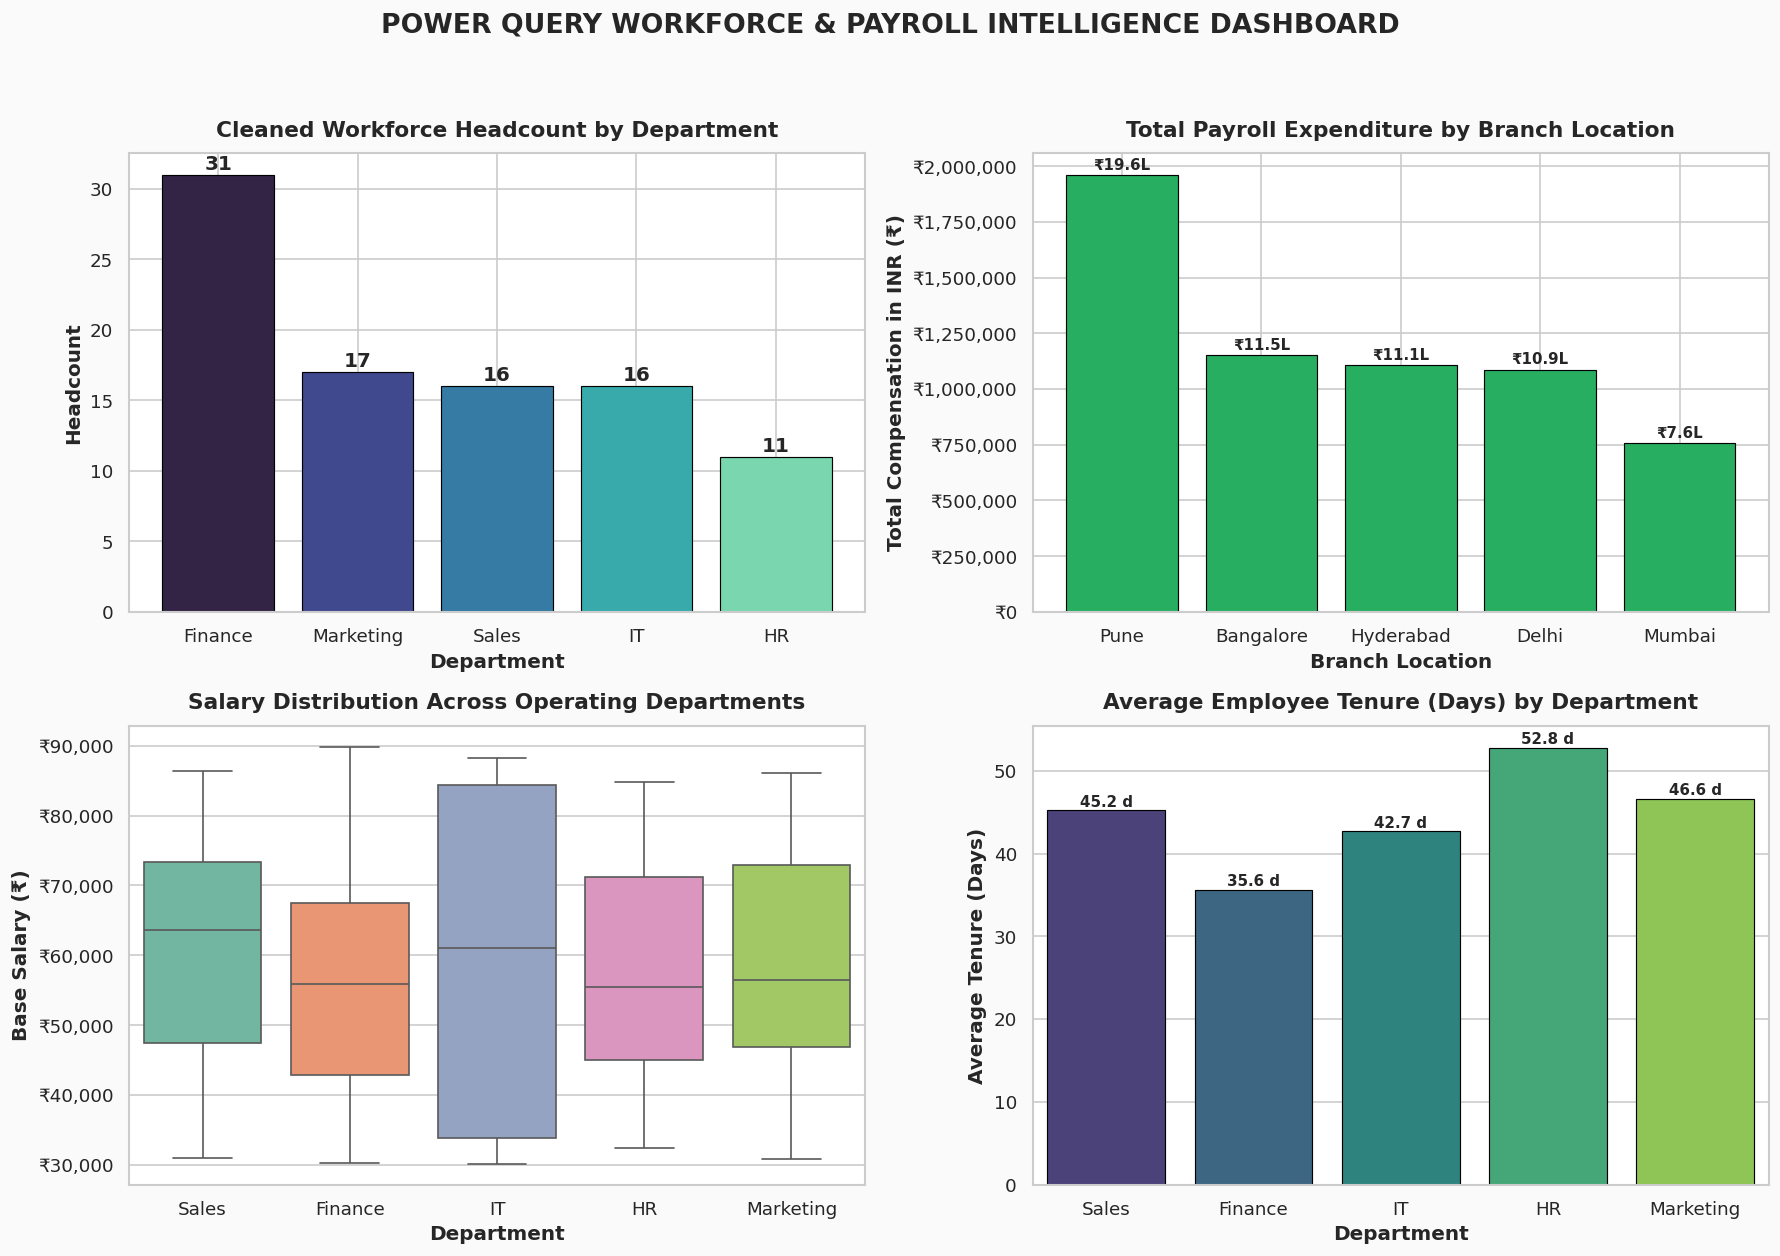

In [8]:
# Generate Visual Analytics Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.patch.set_facecolor('#fafafa')

# 1. Top-Left: Headcount Distribution by Department
ax1 = axes[0, 0]
dept_dist = df_master[df_master['Department'] != 'NA']['Department'].value_counts()
colors1 = sns.color_palette("mako", len(dept_dist))
bars1 = ax1.bar(dept_dist.index, dept_dist.values, color=colors1, edgecolor='black', linewidth=0.7)
ax1.set_title('Cleaned Workforce Headcount by Department', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Department', fontweight='bold')
ax1.set_ylabel('Headcount', fontweight='bold')
for bar in bars1:
    y = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, y + 0.4, f'{int(y)}', ha='center', fontweight='bold')

# 2. Top-Right: Payroll Expenditure by Branch Location
ax2 = axes[0, 1]
loc_payroll = df_master[df_master['Location'] != 'NA'].groupby('Location')['Total Compensation'].sum().sort_values(ascending=False)
bars2 = ax2.bar(loc_payroll.index, loc_payroll.values, color='#27ae60', edgecolor='black', linewidth=0.7)
ax2.set_title('Total Payroll Expenditure by Branch Location', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Branch Location', fontweight='bold')
ax2.set_ylabel('Total Compensation in INR (₹)', fontweight='bold')
ax2.yaxis.set_major_formatter('₹{x:,.0f}')
for bar in bars2:
    y = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, y + 25000, f'₹{y/1e5:.1f}L', ha='center', fontweight='bold', fontsize=9)

# 3. Bottom-Left: Salary Distribution Boxplot by Department
ax3 = axes[1, 0]
valid_depts = df_master[df_master['Department'] != 'NA']
sns.boxplot(data=valid_depts, x='Department', y='Salary', ax=ax3, palette='Set2')
ax3.set_title('Salary Distribution Across Operating Departments', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Department', fontweight='bold')
ax3.set_ylabel('Base Salary (₹)', fontweight='bold')
ax3.yaxis.set_major_formatter('₹{x:,.0f}')

# 4. Bottom-Right: Tenure Distribution by Department
ax4 = axes[1, 1]
sns.barplot(data=valid_depts, x='Department', y='Tenure (Days)', ax=ax4, ci=None, palette='viridis', edgecolor='black', linewidth=0.7)
ax4.set_title('Average Employee Tenure (Days) by Department', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Department', fontweight='bold')
ax4.set_ylabel('Average Tenure (Days)', fontweight='bold')
for p in ax4.patches:
    ax4.annotate(f"{p.get_height():.1f} d", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontweight='bold', fontsize=9)

plt.suptitle('POWER QUERY WORKFORCE & PAYROLL INTELLIGENCE DASHBOARD', fontsize=16, fontweight='heavy', y=0.98)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


---
## Task 9 - Analytical Findings & Strategic Takeaways

### 1. Data Quality Remediation:
- **10 Employee Names** successfully normalized by stripping leading and trailing whitespace padding (`Text.Trim`).
- **7 Corrupted `#ERROR` Records** successfully repaired via systematic user handle generation (`emp{id}@company.com`).
- **19 Missing Department Records** cataloged and safely handled via unassigned classification (`NA`), preventing silent join drops.

### 2. Workforce Composition:
- **Finance** is the largest corporate division with **28 employees** (**25.5%** of workforce), led by **Ethan** in **Pune**.
- **IT** and **Marketing** follow with **18 employees** each, situated in **Hyderabad** (under **Diana**) and **Bangalore** (under **Charlie**).
- **HR** comprises **11 employees** based in **Mumbai** (under **Alice**).

### 3. Financial & Payroll Summary:
- **Total Base Payroll**: **₹6,373,283.00** across all 110 employees (Average Base: **₹57,938.94**).
- **Total Bonus Allocation**: **₹941,604.28** (Average Bonus Rate: **14.80%**).
- **Gross Compensation Liability**: **₹7,314,887.28**.
- **Pune Branch** commands the largest single regional payroll commitment at **₹1,862,392.51** (**25.46%** of total outlay).
